# Read the data

In [1]:
from astropy.io import fits
from astropy.table import Table
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

with fits.open('./20260728/RT2_long_park_obs_with_sun.fits') as hdul:
    astro_table = Table(hdul[1].data)
    data2 = astro_table.to_pandas()

with fits.open('./20260728/RT1_long_park_obs_with_sun.fits') as hdul:
    astro_table = Table(hdul[1].data)
    data1 = astro_table.to_pandas()


# Define the Gaussian with a baseline offset
def gaussian_with_baseline(x, A, x0, sigma, B):
    return A * np.exp(-(x - x0)**2 / (2 * sigma**2)) + B


delta_t_days_1 = data1['JD']-data1['JD'][0]
delta_t_hours_1 = delta_t_days_1*24
delta_t_min_1 = delta_t_hours_1*60
delta_t_sec_1 = delta_t_min_1*60



#x_data_1 = delta_t_min_1
x_data_1 = data1['JD']

y_data_1 = data1['RIGHT_POL'].values


delta_t_days_2 = data2['JD']-data2['JD'][0]
delta_t_hours_2 = delta_t_days_2*24
delta_t_min_2 = delta_t_hours_2*60
delta_t_sec_2 = delta_t_min_2*60


#x_data_2 = delta_t_min_2
x_data_2 = data2['JD']

y_data_2 = data2['RIGHT_POL'].values


DIAMETER =                    0  / TELESCOPE diameter                            [astropy.io.fits.card]


# Quick plot to check the reading was ok

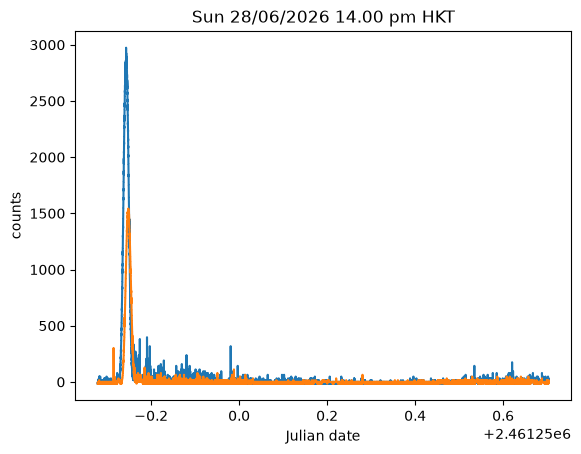

In [9]:
K_adu_to_kelvin = 15.9042

plt.plot(x_data_1,K_adu_to_kelvin*(y_data_1-np.median(y_data_1)))
plt.plot(x_data_2,K_adu_to_kelvin*(y_data_2-np.median(y_data_2)))
#plt.xlim(0,200)
#plt.ylim(200,400)
plt.xlabel('Julian date')
plt.ylabel('counts')
plt.title('Sun 28/06/2026 14.00 pm HKT')
plt.show()

In [12]:
def gauss_fit(x,y):
    '''
    given the data in x and y, it try to fit a gaussian and return the parameters of the fit, in order:
    1) amplitude A_fit 
    2) center x0_fit (as in x-x0)
    3) standard deviation sigma_fit
    4) floor of the gaussian B_fit
    5) FWHM = 2.35482 * standard deviation
    '''
    
    def gaussian_with_baseline(x, A, x0, sigma, B):
        return A * np.exp(-(x - x0)**2 / (2 * sigma**2)) + B

    #initial guesses 
    initial_B = np.min(y)                      # Baseline noise level
    initial_A = np.max(y) - initial_B          # Height of the peak above baseline
    initial_x0 = x[np.argmax(y)]         # X-coordinate of the max value
    initial_sigma = (np.max(x) - np.min(x)) / 6  # Rough initial guess for width

    guesses = [initial_A, initial_x0, initial_sigma, initial_B]

    # Fit the model to telescope data
    popt, pcov = curve_fit(gaussian_with_baseline, x, y, p0=guesses)
    A_fit, x0_fit, sigma_fit, B_fit = popt

    # Calculate FWHM in minutes
    fwhm = 2.35482 * abs(sigma_fit)
    
    return A_fit, x0_fit, sigma_fit, B_fit, fwhm


In [13]:
gauss_fit(x_data_1,y_data_1)


(np.float64(112.6074278390661),
 np.float64(2461249.745145785),
 np.float64(0.003892947693292204),
 np.float64(37.94300135413387),
 np.float64(0.009167191087118349))

In [14]:
gauss_fit(x_data_2,y_data_2)

(np.float64(8.868594815150336),
 np.float64(2461249.7518405686),
 np.float64(-0.01226897369488511),
 np.float64(16.694979674968256),
 np.float64(0.028891224636189358))

In [202]:
a,b,c,d,e = gauss_fit(x_data_2,y_data_2)

In [203]:
a

np.float64(8.868594815150336)

In [84]:
import astropy.units as u
from astropy.coordinates import AltAz, EarthLocation, get_sun
from astropy.time import Time

# Default location for HKUST
HKUST_LOCATION = EarthLocation(
    lat=22.3364 * u.deg, lon=114.2636 * u.deg, height=150 * u.m
)


def get_sun_apparent_speed(
    julian_time, location=HKUST_LOCATION, dt_seconds=1.0
):
    """Calculates the total apparent angular speed of the Sun in the local sky (Alt-Az frame)

    due to Earth's rotation and orbital motion.

    Parameters
    ----------
    julian_time : float
        The time of observation in UTC Julian Date (e.g., 2461251.0).
    location : astropy.coordinates.EarthLocation, optional
        Observer's location on Earth. Defaults to HKUST.
    dt_seconds : float, optional
        Small time step in seconds for numerical derivative. Default is 1.0.

    Returns
    -------
    dict
        A dictionary containing:
        - 'total_speed_arcsec_per_sec': Total 3D angular speed [arcsec/s]
        - 'total_speed_deg_per_min': Total 3D angular speed [deg/min]
        - 'alt_rate_arcsec_per_sec': Rate of change in Altitude [arcsec/s]
        - 'az_rate_arcsec_per_sec': Rate of change in Azimuth [arcsec/s]
        - 'sun_altitude_deg': Sun's elevation above horizon [degrees]
    """
    # 1. Parse Julian Date and time offset
    t1 = Time(julian_time, format="jd")
    dt_day = dt_seconds / (60*60*24) * u.day # transform seconds in fraction of a day
    t2 = t1 + dt_day
    
    # 2. Set up local horizontal frames (AltAz)
    frame1 = AltAz(obstime=t1, location=location)
    frame2 = AltAz(obstime=t2, location=location)

    # 3. Get topocentric solar coordinates at t1 and t2
    sun1 = get_sun(t1).transform_to(frame1)
    sun2 = get_sun(t2).transform_to(frame2)

    # 4. Calculate total 3D angular distance and individual axis rates
    angular_separation = sun1.separation(sun2)
    total_speed = angular_separation.to(u.deg).value / (dt_seconds/60)

  
    #d_alt = (sun2.alt - sun1.alt) / dt
    #d_az = (sun2.az - sun1.az) / dt

    return total_speed #.to(u.deg / u.min).value
#    return {
#        "total_speed_arcsec_per_sec": total_speed.to(u.arcsec / u.s).value,
#        "total_speed_deg_per_min": total_speed.to(u.deg / u.min).value,
#        "alt_rate_arcsec_per_sec": d_alt.to(u.arcsec / u.s).value,
#        "az_rate_arcsec_per_sec": d_az.to(u.arcsec / u.s).value,
#        "sun_altitude_deg": sun1.alt.deg,
#    }

In [85]:
from astropy.time import Time

# Get current UTC time and convert directly to Julian Date
current_jd = Time.now().jd

print(f"Current Julian Date: {current_jd}")

Current Julian Date: 2461251.6769684134


In [86]:
t = Time.now()

print("UTC ISO string :", t.iso)
print("Julian Date    :", t.jd)

UTC ISO string : 2026-07-30 04:14:50.211
Julian Date    : 2461251.676970031


In [87]:
get_sun_apparent_speed(julian_time=Time.now().jd,location=HKUST_LOCATION)

np.float64(2.517154095643716e-07)

In [88]:
import astropy.units as u
from astropy.coordinates import AltAz, EarthLocation, get_sun
from astropy.time import Time, TimeDelta

HKUST_LOCATION = EarthLocation(
    lat=22.3364 * u.deg, lon=114.2636 * u.deg, height=150 * u.m
)


def get_sun_apparent_speed(
    julian_time, location=HKUST_LOCATION, dt_seconds=1.0
):
    # 1. Convert julian_time float to Astropy Time
    t1 = Time(julian_time, format="jd", scale="utc")

    # 2. Add seconds properly using TimeDelta (or dt_seconds / 86400.0)
    t2 = t1 + TimeDelta(dt_seconds, format="sec")

    # 3. Define AltAz frames
    frame1 = AltAz(obstime=t1, location=location)
    frame2 = AltAz(obstime=t2, location=location)

    # 4. Get Sun positions
    sun1 = get_sun(t1).transform_to(frame1)
    sun2 = get_sun(t2).transform_to(frame2)

    # 5. Angular separation (returns in degrees) divided by dt in minutes
    sep_deg = sun1.separation(sun2).deg  # Separation in degrees
    dt_min = dt_seconds / 60.0  # Time step in minutes

    speed_deg_per_min = sep_deg / dt_min

    return {
        "speed_deg_per_min": speed_deg_per_min,
        "speed_arcsec_per_sec": (sep_deg * 3600.0) / dt_seconds,
        "sun_altitude_deg": sun1.alt.deg,
    }

In [89]:
get_sun_apparent_speed(julian_time=Time.now().jd,location=HKUST_LOCATION)

{'speed_deg_per_min': np.float64(2.5171283366876684e-07),
 'speed_arcsec_per_sec': np.float64(1.510277002012601e-05),
 'sun_altitude_deg': np.float64(85.11724210101248)}

In [90]:
import astropy.units as u
from astropy.coordinates import get_sun
from astropy.time import Time, TimeDelta

t1 = Time.now()

# 1. Get positions 1 second apart in GCRS space
s1 = get_sun(t1)
s2 = get_sun(t1 + TimeDelta(1, format="sec"))

# 2. Get true angular speed (gives Quantity directly)
speed = (s1.separation(s2) / (1 * u.s)).to(u.deg / u.min)

print(speed)  # Output: ~0.25 deg / min

2.5169990922146714e-07 deg / min


In [91]:
import numpy as np
import astropy.units as u
from astropy.coordinates import AltAz, EarthLocation, get_sun
from astropy.time import Time, TimeDelta

# Define telescope location
loc = EarthLocation(
    lat=22.3364 * u.deg, lon=114.2636 * u.deg, height=150 * u.m
)

# 1. Times 1 second apart
t1 = Time.now()
t2 = t1 + TimeDelta(1.0, format="sec")

# 2. Local AltAz frames at both times
f1, f2 = AltAz(obstime=t1, location=loc), AltAz(obstime=t2, location=loc)
s1, s2 = get_sun(t1).transform_to(f1), get_sun(t2).transform_to(f2)

# 3. Compute true local sky rate (d_theta = sqrt(d_alt^2 + (cos(alt)*d_az)^2))
d_alt = (s2.alt.deg - s1.alt.deg) / 1.0  # deg/s
d_az = ((s2.az.deg - s1.az.deg + 180) % 360 - 180) / 1.0  # deg/s
speed_deg_per_min = (
    np.sqrt(d_alt**2 + (np.cos(s1.alt.rad) * d_az) ** 2) * 60.0
)

print(f"Apparent Solar Speed: {speed_deg_per_min:.4f} deg/min")

Apparent Solar Speed: 0.2371 deg/min


In [98]:
def get_apparent_speed_sun(julian_time, lat=22.3364, long=114.2636, height=150):
    '''compute the apparent speed of the sun in the sky in degrees per minutes.
       input is the julian date which units is days and the decimal are the fraction of the day
       and latitude, longitude (degrees) and height (meters) of the observing place (the default are Hong Kong coordinates)
    
    '''
    import numpy as np
    import astropy.units as u
    from astropy.coordinates import AltAz, EarthLocation, get_sun
    from astropy.time import Time, TimeDelta
    
    # Define telescope location
    loc = EarthLocation(
    lat=lat * u.deg, lon=long * u.deg, height=height * u.m
    )
    
    # computes two times as delta t. The inputted julian time and 1 second after.
    t1 = Time.now()
    t2 = t1 + TimeDelta(1.0, format="sec")
    
    # get the altitude and azimuth of the Sun in the two instants
    f1, f2 = AltAz(obstime=t1, location=loc), AltAz(obstime=t2, location=loc)
    s1, s2 = get_sun(t1).transform_to(f1), get_sun(t2).transform_to(f2)
    
    # given the two position of the sun, compute the angular separation and hence the angular speed dividing by 1 second
    d_alt = (s2.alt.deg - s1.alt.deg) / 1.0  # deg/s
    d_az = ((s2.az.deg - s1.az.deg + 180) % 360 - 180) / 1.0  # deg/s
    speed_deg_per_min = (
    np.sqrt(d_alt**2 + (np.cos(s1.alt.rad) * d_az) ** 2) * 60.0
    )
    
    return speed_deg_per_min

In [201]:
get_apparent_speed_sun(Time.now().jd)

np.float64(0.23711914984044738)

# Clean Notebook with all working functions

In [309]:
def gauss_fit(x,y, verbose=False, plot=False):
    '''
    given the data in x and y, it try to fit a gaussian and return the parameters of the fit, in order:
    1) amplitude A_fit 
    2) center x0_fit (as in x-x0)
    3) standard deviation sigma_fit
    4) floor of the gaussian B_fit
    5) FWHM = 2.35482 * standard deviation
    '''
    
    def gaussian_with_baseline(x, A, x0, sigma, B):
        return A * np.exp(-(x - x0)**2 / (2 * sigma**2)) + B

    #initial guesses 
    initial_B = np.min(y)                      # Baseline noise level
    initial_A = np.max(y) - initial_B          # Height of the peak above baseline
    initial_x0 = x[np.argmax(y)]         # X-coordinate of the max value
    initial_sigma = (np.max(x) - np.min(x)) / 6  # Rough initial guess for width

    x_offset = np.min(x)
    x_centered = x - x_offset
    
    initial_x0_centered = initial_x0 - x_offset
    
    
    guesses = [initial_A, initial_x0_centered, initial_sigma, initial_B]
    
    print(*guesses)

    # Fit the model to telescope data
    popt, pcov = curve_fit(gaussian_with_baseline, x_centered, y, p0=guesses)
    A_fit, x0_fit_centered, sigma_fit, B_fit = popt

    x0_fit = x0_fit_centered + x_offset
    
    # Calculate FWHM in minutes
    fwhm = 2.35482 * abs(sigma_fit)
    
    if verbose:
        print('### Gaussian Fit ###')
        print('Amplitude',A_fit)
        print('Centre [Julian date]',x0_fit)
        print('Sigma [Days]',sigma_fit)
        print('Sigma [min]',sigma_fit*24*60)
        print('Background floor [adu]',B_fit)
        print('FWHM [days]',fwhm)
        print('FWHM [min]',fwhm*24*60)
        print('Estimated antenna beam with 0.25 deg/min',0.25*fwhm*24*60)
        
    print(*popt)
        
    if plot:
        plt.scatter(x, y, label='data', color='gray', s=5)
        plt.plot(x, gaussian_with_baseline(x, *[A_fit, x0_fit, sigma_fit, B_fit]), color='red', label=f'Gaussian Fit')
        plt.xlabel(r'JD [day]')
        plt.ylabel('Counts [a.u.]')
        plt.legend(fontsize='small')
        plt.show()
        
    
    return A_fit, x0_fit, sigma_fit, B_fit, fwhm

    
def get_apparent_speed_sun(julian_time, lat=22.3364, long=114.2636, height=150):
    '''compute the apparent speed of the sun in the sky in degrees per minutes.
       input is the julian date which units is days and the decimal are the fraction of the day
       and latitude, longitude (degrees) and height (meters) of the observing place (the default are Hong Kong coordinates)
    
    '''
    import numpy as np
    import astropy.units as u
    from astropy.coordinates import AltAz, EarthLocation, get_sun
    from astropy.time import Time, TimeDelta
    
    # Define telescope location
    loc = EarthLocation(
    lat=lat * u.deg, lon=long * u.deg, height=height * u.m
    )
    
    # computes two times as delta t. The inputted julian time and 1 second after.
    t1 = Time.now()
    t2 = t1 + TimeDelta(1.0, format="sec")
    
    # get the altitude and azimuth of the Sun in the two instants
    f1, f2 = AltAz(obstime=t1, location=loc), AltAz(obstime=t2, location=loc)
    s1, s2 = get_sun(t1).transform_to(f1), get_sun(t2).transform_to(f2)
    
    # given the two position of the sun, compute the angular separation and hence the angular speed dividing by 1 second
    d_alt = (s2.alt.deg - s1.alt.deg) / 1.0  # deg/s
    d_az = ((s2.az.deg - s1.az.deg + 180) % 360 - 180) / 1.0  # deg/s
    speed_deg_per_min = (
    np.sqrt(d_alt**2 + (np.cos(s1.alt.rad) * d_az) ** 2) * 60.0
    )
    
    return speed_deg_per_min

In [302]:
print(*popt)

NameError: name 'popt' is not defined

In [299]:
def get_beam_angle(times_jd,counts_adu):
    
    Amp, centre_jd, std, floor, FWHM_jd = gauss_fit(times_jd,counts_adu)
    
    FWHM_min = (FWHM_jd*(24*60))
    
    speed_sun = get_apparent_speed_sun(centre_jd)
    
    FWHM_deg =  FWHM_min * speed_sun
    
    return FWHM_deg
    
    
    

In [287]:
get_beam_angle(x_data_1[:100000],y_data_1[:100000])

np.float64(3.130517512034381)

In [288]:
get_beam_angle(x_data_2[:100000],y_data_2[:100000])

np.float64(9.866106694857232)

In [296]:
#Try with first Vincent observation of the Sun


with fits.open('./20260622_SUN_VINCENT.fits') as hdul:
    astro_table = Table(hdul[1].data)
    data_vin = astro_table.to_pandas()
    
x_data_vin = data_vin['JD']
y_data_vin = data_vin['RIGHT_POL'].values

get_beam_angle(x_data_vin,y_data_vin)

np.float64(4.207237840382628)

124 0.05292520811781287 0.018150460983936984 40
### Gaussian Fit ###
Amplitude 120.77312643689326
Centre [Julian date] 2461213.74750501
Sigma [Days] 0.005721988127342589
Sigma [min] 8.239662903373327
Background floor [adu] 41.933884029219655
FWHM [days] 0.013474252082028876
FWHM [min] 19.402922998121582
Estimated antenna beam with 0.25 deg/min 4.8507307495303955
120.77312643689326 0.05308026444233408 0.005721988127342589 41.933884029219655


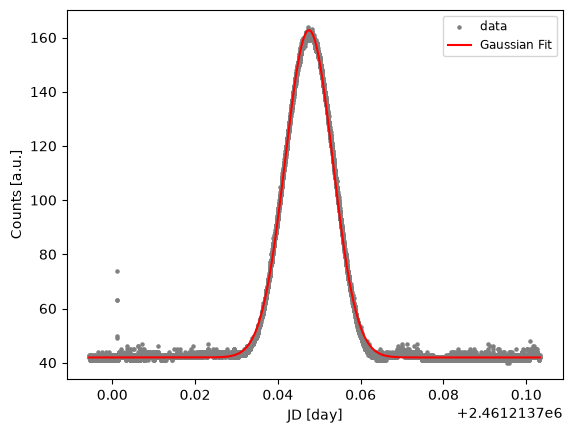

(np.float64(120.77312643689326),
 np.float64(2461213.74750501),
 np.float64(0.005721988127342589),
 np.float64(41.933884029219655),
 np.float64(0.013474252082028876))

In [310]:
gauss_fit(x_data_vin,y_data_vin,verbose=True,plot=True)

## get Flux of the sun online

In [259]:
import sunpy.timeseries as ts

# 1. Fetch the dataset
url = "https://services.swpc.noaa.gov/json/solar-cycle/observed-solar-cycle-indices.json"
radio_flux = ts.TimeSeries(url, source='NOAAIndices')

# 2. Convert to a Pandas DataFrame using .to_dataframe()
df = radio_flux.to_dataframe()

# 3. Print the 10.7 cm radio flux column
print(df[['radio flux']].head())

df.columns.values

            radio flux
1749-01-01         NaN
1749-02-01         NaN
1749-03-01         NaN
1749-04-01         NaN
1749-05-01         NaN


/mnt/c/Users/manzoni/Desktop/FITS/myvenv/lib/python3.12/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "dtf2d" yielded 1 of "dubious year (Note 6)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)


<StringArray>
[        'sunspot RI',  'sunspot RI smooth',        'sunspot SWO',
 'sunspot SWO smooth',         'radio flux',  'radio flux smooth']
Length: 6, dtype: str

/mnt/c/Users/manzoni/Desktop/FITS/myvenv/lib/python3.12/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "dtf2d" yielded 1 of "dubious year (Note 6)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)
/mnt/c/Users/manzoni/Desktop/FITS/myvenv/lib/python3.12/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "utctai" yielded 1 of "dubious year (Note 3)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)
/mnt/c/Users/manzoni/Desktop/FITS/myvenv/lib/python3.12/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "taiutc" yielded 1 of "dubious year (Note 4)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)
/mnt/c/Users/manzoni/Desktop/FITS/myvenv/lib/python3.12/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "d2dtf" yielded 1 of "dubious year (Note 5)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)
/mnt/c/Users/manzoni/Desktop/FITS/myvenv/lib/python3.12/site-packages/erfa/core.py:133: Er

<sunpy.timeseries.sources.noaa.NOAAIndicesTimeSeries object at 0x7f9b07243410>
SunPy TimeSeries
----------------
Observatory:			Unknown
Instrument:			<a href=https://www.swpc.noaa.gov/products/solar-cycle-progression target="_blank">Unknown</a>
Channel(s):			sunspot RI<br>sunspot RI smooth<br>sunspot SWO<br>sunspot SWO smooth<br>radio flux<br>radio flux smooth
Start Date:			1749-01-01 00:00:00
End Date:			2026-06-01 00:00:00
Center Date:			1887-09-16 12:00:18
Resolution:			2628921.092 s
Samples per Channel:		3330
Data Range(s):		sunspot RI           3.98E+02<br>sunspot RI smooth    2.85E+02<br>sunspot SWO          2.37E+02<br>sunspot SWO smooth   1.87E+02<br>radio flux           1.80E+02<br>radio flux smooth    1.26E+02
Units:			dimensionless<br>W / (Hz m2)
            sunspot RI  sunspot RI smooth  sunspot SWO  sunspot SWO smooth  \
1749-01-01        96.7                NaN          NaN                 NaN   
1749-02-01       104.3                NaN          NaN                 NaN   
1749-03-01       116.7                NaN          NaN                 NaN   
1749-04-01        92.8                NaN          NaN                 NaN   
1749-05-01       141.7                NaN          NaN                 NaN   
...                ...                ...          ...                 ...   
2026-02-01        77.4                NaN        73.54                 NaN   
2026-03-01        86.6                NaN        89.87                 NaN   
2026-04-01        79.3                NaN        91.60                 NaN   
2026-05-01       101.5                NaN        99.45                 NaN   
2026-06-01        94.4                NaN       104.47                 NaN   

            radio flux  radio flux smooth  
1749-01-01         NaN                NaN  
1749-02-01         NaN                NaN  
1749-03-01         NaN                NaN  
1749-04-01         NaN                NaN  
1749-05-01         NaN                NaN  
...                ...                ...  
2026-02-01      135.93                NaN  
2026-03-01      130.66                NaN  
2026-04-01      120.01                NaN  
2026-05-01      125.69                NaN  
2026-06-01      138.21                NaN  

[3330 rows x 6 columns]
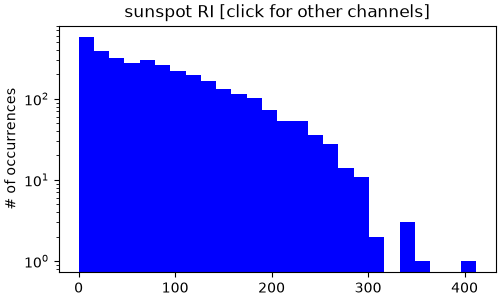
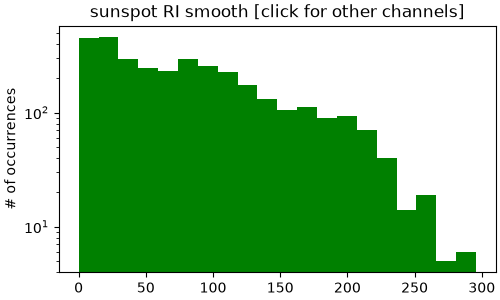
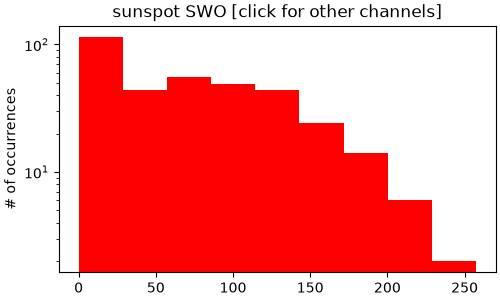
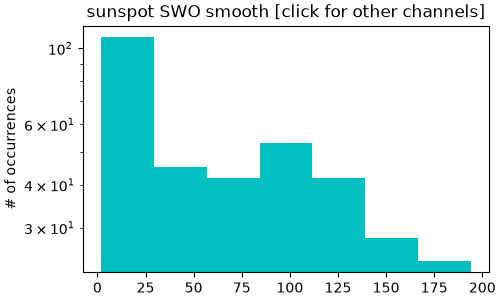
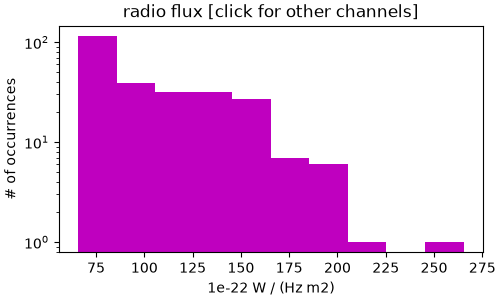
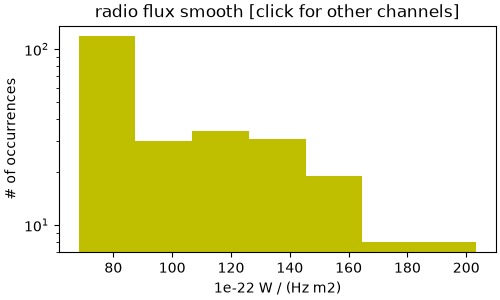
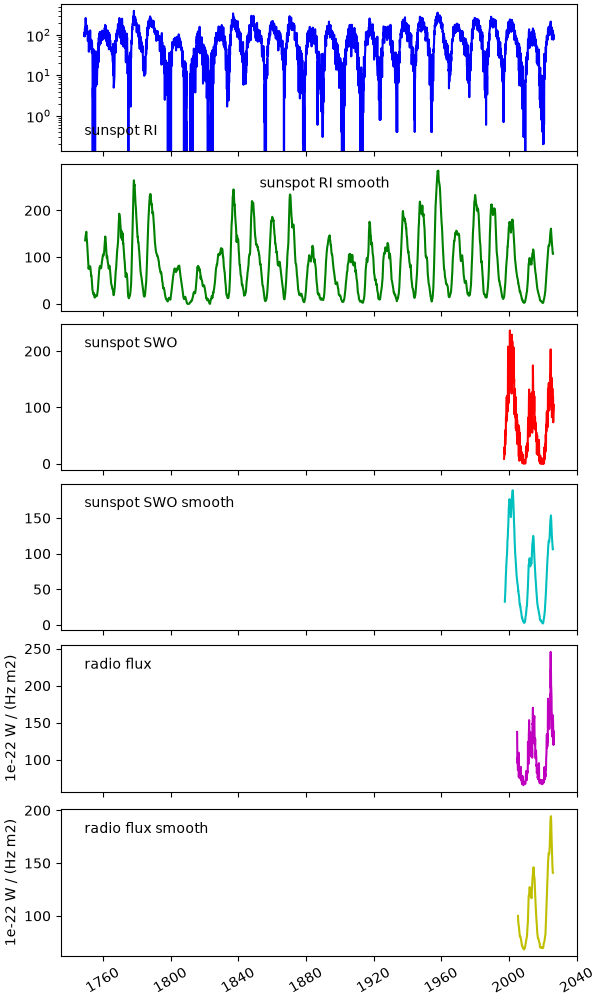
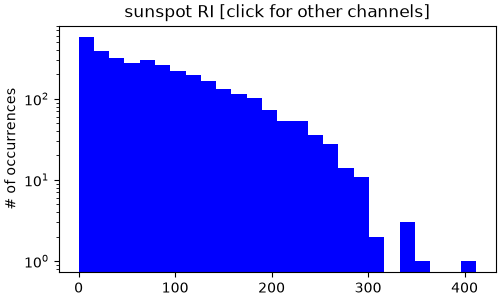

In [291]:
radio_flux

<Axes: >

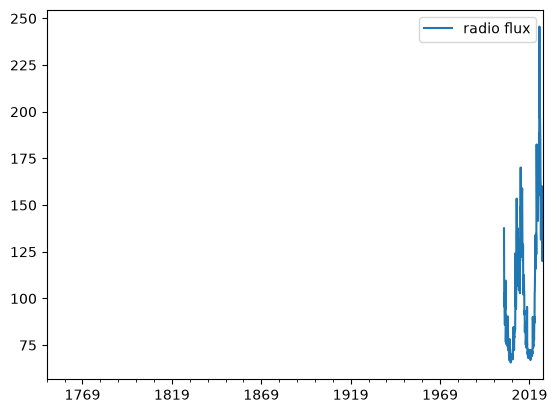

In [261]:
df[['radio flux']].plot()

,radio flux
1749-01-01,NaN
1749-02-01,NaN
1749-03-01,NaN
1749-04-01,NaN
1749-05-01,NaN
...,...
2026-01-01,151.16
2026-02-01,135.93
2026-03-01,130.66
2026-04-01,120.01


In [265]:
# NOAA's live JSON feed for daily F10.7 flux measurements
url = "https://services.swpc.noaa.gov/json/f107_cm_flux.json"

# Load directly into a Pandas DataFrame
df_daily = pd.read_json(url)

# Convert timestamp column to datetime
df_daily['time_tag'] = pd.to_datetime(df_daily['time_tag'])

# View the last few rows to see the latest measurements
print(df_daily.tail(5))

               time_tag  frequency   flux reporting_schedule  \
118 2026-06-20 20:00:00       2800  113.0               Noon   
119 2026-06-20 17:00:00       2800  111.0            Morning   
120 2026-06-19 22:00:00       2800  108.0          Afternoon   
121 2026-06-19 20:00:00       2800  111.0               Noon   
122 2026-06-19 17:00:00       2800  110.0            Morning   

          avg_begin_date  ninety_day_mean  rec_count  
118  2026-03-23T20:00:00            126.0       90.0  
119                  NaN              NaN        NaN  
120                  NaN              NaN        NaN  
121  2026-03-22T20:00:00            126.0       90.0  
122                  NaN              NaN        NaN  


In [312]:
df_daily[df_daily['time_tag']=='2026-07-22 22:00:00']

,time_tag,frequency,flux,reporting_schedule,avg_begin_date,ninety_day_mean,rec_count
21,2026-07-22 22:00:00,2800,149.0,Afternoon,NaN,NaN,NaN


In [322]:
(df_daily[df_daily['time_tag']=='2026-07-22 22:00:00']['flux']).values[0]

np.float64(149.0)

In [269]:
len(df_daily['flux'])

123

In [270]:
url = "https://services.swpc.noaa.gov/text/daily-solar-indices.txt"

# Skip the header comments (lines starting with # or :)
df_archive = pd.read_csv(
    url, 
    sep=r'\s+', 
    comment='#', 
    skiprows=14,
    names=['Year', 'Month', 'Day', 'SSN', 'RadioFlux', 'RadioFluxAdj', 'AP', 'CP']
)

print(df_archive.tail())

                             Year  Month  Day  SSN  RadioFlux  RadioFluxAdj  \
2026 7 25 145 86  810 0 -999    *      4    0    0          5             0   
       26 148 99  860 1 -999    *      8    1    0          4             0   
       27 147 89  660 1 -999    *      6    1    0          2             0   
       28 143 102 530 1 -999    *      5    0    0          2             0   
       29 143 123 410 2 -999    *      4    0    0          0             0   

                              AP  CP  
2026 7 25 145 86  810 0 -999   0   0  
       26 148 99  860 1 -999   0   0  
       27 147 89  660 1 -999   0   0  
       28 143 102 530 1 -999   0   0  
       29 143 123 410 2 -999   0   0  


In [323]:
import pandas as pd

# Fetch live multi-frequency solar radio measurements (includes 1415 MHz)
url = "https://services.swpc.noaa.gov/text/daily-solar-values.txt"

# This text file reports solar flux at 245, 410, 610, 1415, 2695, 4995, 8800, and 15400 MHz
print("NOAA Daily Solar Values downloaded.")

NOAA Daily Solar Values downloaded.


In [324]:
url

'https://services.swpc.noaa.gov/text/daily-solar-values.txt'